In [ ]:
%pip install -q roboflow

In [ ]:
!pip install -q roboflow

import os
from roboflow import Roboflow

# Pastikan kita berada di direktori /content
os.chdir('/content')

rf = Roboflow(api_key="tFBEO0PLcFXNn2ApeQjG")
project = rf.workspace("ingridients").project("ingridients-n4i2y")
version = project.version(2)
dataset = version.download("yolov8")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Ingridients-2 in yolov8:: 100%|██████████| 13852/13852 [00:01<00:00, 8066.69it/s] 


### 1. Memeriksa Konfigurasi Kelas dan Dataset
Kita akan membaca file `data.yaml` untuk memverifikasi daftar bahan makanan (kelas) yang berhasil diunduh beserta jumlah gambar pada masing-masing split (*train*, *validation*, dan *test*).

In [ ]:
from pathlib import Path
import yaml
import os

# Memaksa path ke folder /content/Ingridients-2
folder_dataset = Path('/content/Ingridients-2')
file_yaml = folder_dataset / "data.yaml"

if not file_yaml.exists():
    # Jika tidak ada, coba cari secara dinamis di subfolder
    pencarian_yaml = list(Path('/content').rglob('data.yaml'))
    if pencarian_yaml:
        file_yaml = pencarian_yaml[0]
        folder_dataset = file_yaml.parent

if file_yaml.exists():
    with open(file_yaml, encoding="utf-8") as f:
        konfigurasi = yaml.safe_load(f)

    nama_kelas = konfigurasi["names"]
    kelas = (
        {int(k): v for k, v in nama_kelas.items()}
        if isinstance(nama_kelas, dict)
        else dict(enumerate(nama_kelas))
    )

    print("🎉 Dataset Berhasil Ditemukan!")
    print("Lokasi dataset:", folder_dataset)
    print("Jumlah kelas:", len(kelas))
    print("\nDAFTAR KELAS BAHAN MAKANAN:")
    for nomor, bahan in kelas.items():
        print(f"{nomor}: {bahan}")

    ekstensi = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
    gambar_per_split = {}

    print("\nJUMLAH GAMBAR:")
    for split in ["train", "valid", "test"]:
        folder = folder_dataset / split / "images"
        if folder.exists():
            gambar = sorted(
                p for p in folder.rglob("*")
                if p.is_file() and p.suffix.lower() in ekstensi
            )
            gambar_per_split[split] = gambar
            print(f"{split}: {len(gambar)} gambar")
        else:
            gambar_per_split[split] = []
            print(f"{split}: Folder tidak ditemukan ({folder})")
else:
    print(f"❌ File data.yaml tetap tidak ditemukan di {file_yaml}.")
    print("Silakan jalankan ulang Sel ke-2 (pengunduhan Roboflow) di atas terlebih dahulu.")

🎉 Dataset Berhasil Ditemukan!
Lokasi dataset: /content/Ingridients-2
Jumlah kelas: 21

DAFTAR KELAS BAHAN MAKANAN:
0: Ayam
1: Bawang Merah
2: Bawang Putih
3: Bayam
4: Cabai Hijau
5: Cabai Merah
6: Daging Kambing
7: Daging Sapi
8: Daun Bawang
9: Ikan
10: Kacang Panjang
11: Kangkung
12: Kol
13: Nasi
14: Tahu
15: Telur
16: Tempe
17: Terong
18: Tomat
19: Udang
20: Wortel

JUMLAH GAMBAR:
train: 6058 gambar
valid: 431 gambar
test: 431 gambar


Cell 4 — Pemeriksaan kualitas dataset (Dataset Validation)

Tujuan: memastikan gambar dan anotasi YOLO dapat dibaca, ID kelas valid, serta mengetahui jumlah objek untuk setiap kelas sebelum training.

In [ ]:
# ============================================
# CELL 4 — FIX DATASET PATH
# Proyek: ChefAI - AI Vision
# Tujuan: memperbaiki lokasi train, validation, test
# ============================================

from pathlib import Path
import yaml

DATASET_DIR = Path("/content/Ingridients-2")
ORIGINAL_YAML = DATASET_DIR / "data.yaml"
FIXED_YAML = DATASET_DIR / "data_che fai.yaml"

# Pastikan struktur dataset benar
assert ORIGINAL_YAML.exists(), (
    f"File konfigurasi tidak ditemukan: {ORIGINAL_YAML}"
)

for folder in ["train/images", "valid/images", "test/images"]:
    p = DATASET_DIR / folder
    print(f"{folder}: {'ADA' if p.is_dir() else 'TIDAK ADA'}")

with open(ORIGINAL_YAML, "r", encoding="utf-8") as f:
    config = yaml.safe_load(f)

# Gunakan path absolut ke folder dataset
config["path"] = str(DATASET_DIR.resolve())
config["train"] = "train/images"
config["val"] = "valid/images"
config["test"] = "test/images"

# Simpan sebagai file konfigurasi baru
with open(FIXED_YAML, "w", encoding="utf-8") as f:
    yaml.safe_dump(config, f, sort_keys=False, allow_unicode=True)

DATA_YAML = str(FIXED_YAML)

print("\nKonfigurasi baru berhasil dibuat:")
print(DATA_YAML)

print("\nIsi konfigurasi:")
print(FIXED_YAML.read_text(encoding="utf-8"))

# Hitung jumlah gambar di setiap split
image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

for split in ["train", "val", "test"]:
    folder = Path(config["path"]) / config[split]
    count = sum(
        1 for p in folder.rglob("*")
        if p.is_file() and p.suffix.lower() in image_extensions
    )
    print(f"Jumlah gambar {split}: {count}")

print("\nJika semua folder ADA dan jumlah gambar lebih dari 0, lanjut ke Cell 7.")

train/images: ADA
valid/images: ADA
test/images: ADA

Konfigurasi baru berhasil dibuat:
/content/Ingridients-2/data_che fai.yaml

Isi konfigurasi:
names:
- Ayam
- Bawang Merah
- Bawang Putih
- Bayam
- Cabai Hijau
- Cabai Merah
- Daging Kambing
- Daging Sapi
- Daun Bawang
- Ikan
- Kacang Panjang
- Kangkung
- Kol
- Nasi
- Tahu
- Telur
- Tempe
- Terong
- Tomat
- Udang
- Wortel
nc: 21
roboflow:
  license: CC BY 4.0
  project: ingridients-n4i2y
  url: https://universe.roboflow.com/ingridients/ingridients-n4i2y/dataset/2
  version: 2
  workspace: ingridients
test: test/images
train: train/images
val: valid/images
path: /content/Ingridients-2

Jumlah gambar train: 6058
Jumlah gambar val: 431
Jumlah gambar test: 431

Jika semua folder ADA dan jumlah gambar lebih dari 0, lanjut ke Cell 7.


Cell 5 — Visualisasi sampel dan anotasi.

Tujuannya memastikan nama bahan dan kotak deteksi sesuai dengan objek sebelum model dilatih.

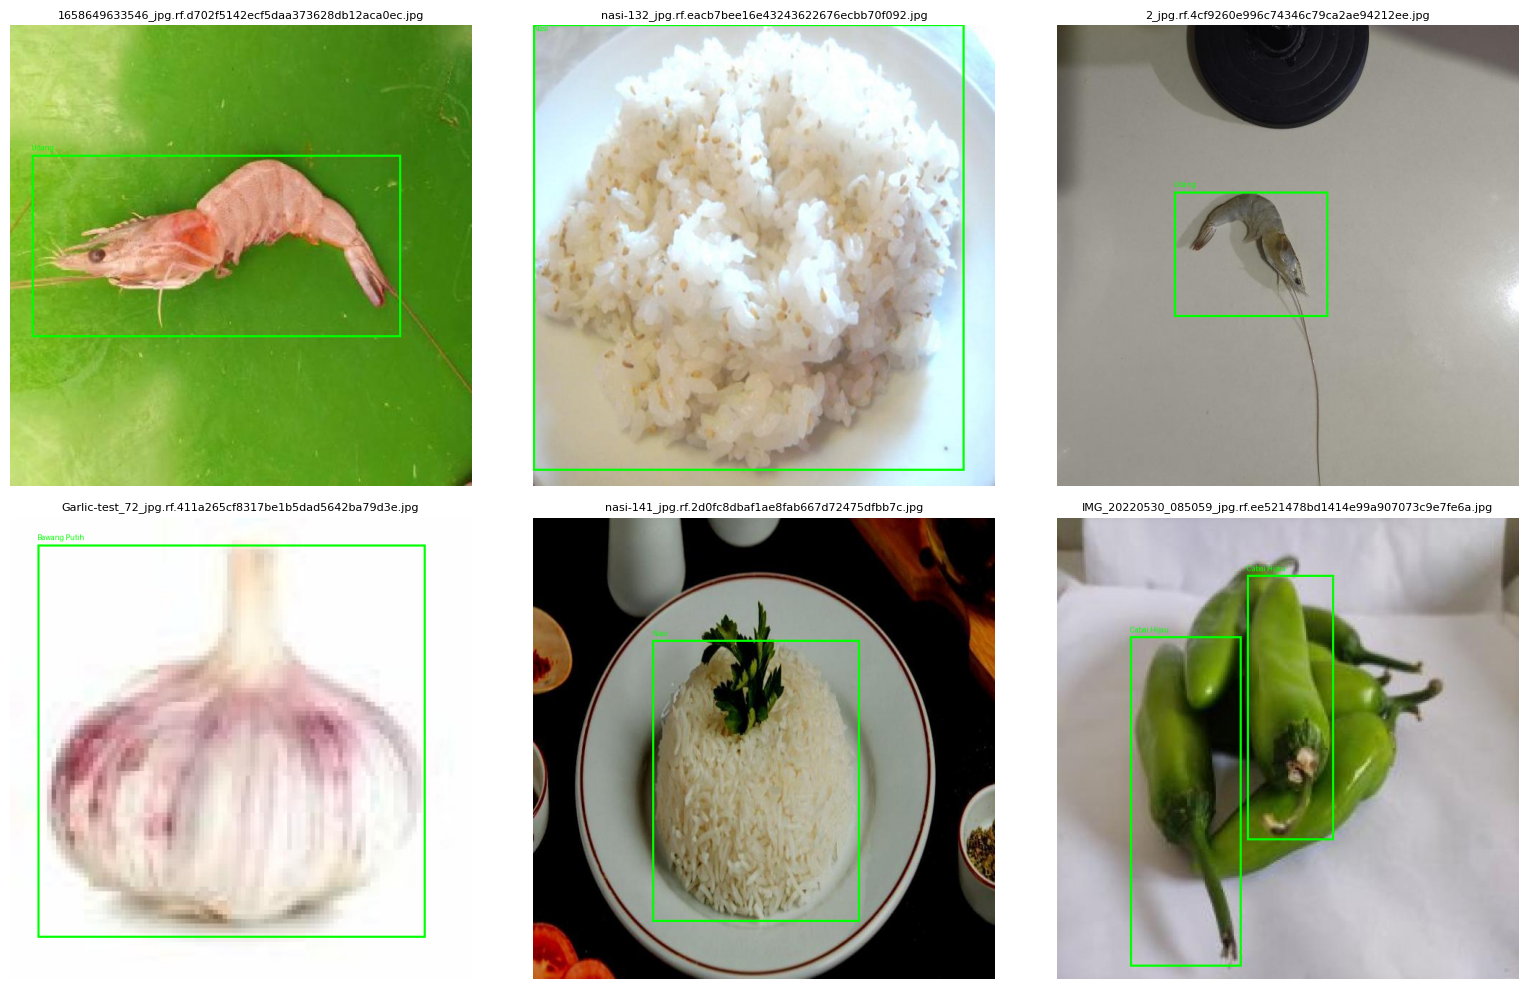

Periksa: apakah kotak dan nama kelas sudah sesuai dengan bahan?


In [ ]:
# ============================================
# CELL 7 — VISUALISASI GAMBAR DAN ANOTASI
# Proyek: ChefAI - AI Vision
# Tujuan: memeriksa apakah label dan kotak objek benar
# ============================================

from pathlib import Path
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import random
import yaml

DATASET_DIR = Path("/content/Ingridients-2")
DATA_YAML = DATASET_DIR / "data_che fai.yaml"

with open(DATA_YAML, "r", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)

names = cfg["names"]
if isinstance(names, dict):
    class_names = {int(k): str(v) for k, v in names.items()}
else:
    class_names = {i: str(v) for i, v in enumerate(names)}

train_images = DATASET_DIR / "train/images"
train_labels = DATASET_DIR / "train/labels"

extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
images = [
    p for p in train_images.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
]

assert images, f"Gambar tidak ditemukan di {train_images}"

samples = random.sample(images, min(6, len(images)))

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for ax, image_path in zip(axes, samples):
    image = Image.open(image_path).convert("RGB")
    draw = ImageDraw.Draw(image)
    width, height = image.size

    relative_path = image_path.relative_to(train_images)
    label_path = train_labels / relative_path.with_suffix(".txt")

    if label_path.exists():
        for line in label_path.read_text(encoding="utf-8").splitlines():
            parts = line.split()
            if len(parts) != 5:
                continue

            class_id = int(parts[0])
            x, y, w, h = map(float, parts[1:])

            x1 = (x - w / 2) * width
            y1 = (y - h / 2) * height
            x2 = (x + w / 2) * width
            y2 = (y + h / 2) * height

            label = class_names.get(class_id, str(class_id))
            draw.rectangle((x1, y1, x2, y2), outline="lime", width=3)
            draw.text((x1, max(0, y1 - 16)), label, fill="lime")

    ax.imshow(image)
    ax.set_title(image_path.name, fontsize=8)
    ax.axis("off")

for ax in axes[len(samples):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Periksa: apakah kotak dan nama kelas sudah sesuai dengan bahan?")

Cell 6 — Training YOLOv8 untuk ChefAI.

 Cell ini akan melatih model menggunakan 21 kelas dataset kamu, menyimpan hasil training ke folder yang tetap, dan menghasilkan best.pt untuk evaluasi berikutnya.

In [ ]:
# ============================================
# CELL 6 — TRAINING YOLOv8 BASELINE
# Proyek: ChefAI - AI Vision
# ============================================

%pip install -q ultralytics

from pathlib import Path
import torch
from ultralytics import YOLO

# 1. Pencarian File Konfigurasi secara Dinamis
possible_yaml_names = ["data_che fai.yaml", "data.yaml"]
found_yaml = None

for name in possible_yaml_names:
    paths = list(Path("/content").rglob(name))
    if paths:
        found_yaml = paths[0]
        break

if found_yaml and found_yaml.is_file():
    DATA_YAML = str(found_yaml.resolve())
    print(f"✓ Berhasil menemukan file konfigurasi di: {DATA_YAML}")
else:
    raise FileNotFoundError(
        "❌ File konfigurasi dataset (data.yaml) tidak ditemukan di /content! "
        "Silakan jalankan ulang Cell 2 (Download Dataset dari Roboflow) "
        "dan Cell 4 (Fix Dataset Path) terlebih dahulu."
    )

# 2. Cek Perangkat GPU / CPU
if torch.cuda.is_available():
    device = 0
    batch_size = 16
    print("GPU aktif:", torch.cuda.get_device_name(0))
else:
    device = "cpu"
    batch_size = 4
    print("GPU tidak tersedia. Training menggunakan CPU.")

# 3. Tentukan Folder Hasil
PROJECT_DIR = "/content/ChefAI/runs"
RUN_NAME = "yolov8n_chefai_v1"

print("Dataset:", DATA_YAML)
print("Epoch: 50")
print("Ukuran gambar: 640")
print("Batch:", batch_size)
print("Folder hasil:", f"{PROJECT_DIR}/{RUN_NAME}")

# 4. Muat Model Pretrained
model = YOLO("yolov8n.pt")

# 5. Mulai Training
train_results = model.train(
    data=DATA_YAML,
    epochs=50,
    imgsz=640,
    batch=batch_size,
    device=device,
    workers=2,
    patience=10,
    project=PROJECT_DIR,
    name=RUN_NAME,
    exist_ok=True,
    plots=True,
    save=True,
    seed=42
)

# 6. Periksa Hasil Training
RUN_DIR = Path(PROJECT_DIR) / RUN_NAME
BEST_MODEL = RUN_DIR / "weights" / "best.pt"
LAST_MODEL = RUN_DIR / "weights" / "last.pt"

print("\n=== STATUS TRAINING ===")
print("Folder hasil:", RUN_DIR)
print("best.pt tersedia:", BEST_MODEL.exists())
print("last.pt tersedia:", LAST_MODEL.exists())

if BEST_MODEL.exists():
    print("\nTRAINING BERHASIL!")
    print("Model terbaik:", BEST_MODEL)
else:
    raise FileNotFoundError(
        "best.pt belum ditemukan. Periksa apakah training "
        "berakhir tanpa error."
    )

print("\nGrafik dan laporan training tersimpan di:", RUN_DIR)

✓ Berhasil menemukan file konfigurasi di: /content/Ingridients-2/data_che fai.yaml
GPU aktif: Tesla T4
Dataset: /content/Ingridients-2/data_che fai.yaml
Epoch: 50
Ukuran gambar: 640
Batch: 16
Folder hasil: /content/ChefAI/runs/yolov8n_chefai_v1
Ultralytics 8.4.187 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Ingridients-2/data_che fai.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, 

Cell 7 — Evaluasi performa model YOLOv8


Tujuan: menghitung Precision, Recall, mAP50, dan mAP50-95 pada validation set.

In [ ]:
# ============================================
# CELL 7 — EVALUASI MODEL CHEFAI
# ============================================

from pathlib import Path
from ultralytics import YOLO
import json

# Lokasi model hasil training Cell 8
BEST_MODEL = Path(
    "/content/ChefAI/runs/yolov8n_chefai_v1/weights/best.pt"
)

# Perbaikan typo: mengubah 'Ingredients-2' menjadi 'Ingridients-2'
DATA_YAML = "/content/Ingridients-2/data_che fai.yaml"

# Pastikan file tersedia
assert BEST_MODEL.exists(), (
    f"Model tidak ditemukan: {BEST_MODEL}. "
    "Pastikan Cell 8 selesai tanpa error."
)
assert Path(DATA_YAML).exists(), f"File data.yaml tidak ditemukan di: {DATA_YAML}"

# Muat model terbaik
model = YOLO(str(BEST_MODEL))

# Evaluasi menggunakan validation set
metrics = model.val(
    data=DATA_YAML,
    split="val",
    imgsz=640,
    plots=True
)

# Ambil metrik utama
scores = {
    "precision": float(metrics.box.mp),
    "recall": float(metrics.box.mr),
    "mAP50": float(metrics.box.map50),
    "mAP50_95": float(metrics.box.map)
}

print("\n=== HASIL EVALUASI CHEFAI ===")
for name, value in scores.items():
    print(f"{name}: {value:.4f} ({value * 100:.2f}%)")

# Simpan hasil evaluasi
report_path = Path(
    "/content/ChefAI/evaluation_report.json"
)
report_path.parent.mkdir(parents=True, exist_ok=True)

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(scores, f, indent=2)

print("\nLaporan evaluasi disimpan di:", report_path)

Ultralytics 8.4.187 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,137,567 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1796.1±410.8 MB/s, size: 40.4 KB)
val: Scanning /content/Ingridients-2/valid/labels.cache... 431 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 431/431 139.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 27/27 4.8it/s 5.6s
                   all        431        514      0.912      0.881      0.918      0.746
                  Ayam         20         28       0.94          1      0.994      0.942
          Bawang Merah         20         35      0.774      0.886      0.938       0.76
          Bawang Putih         19         22      0.887      0.636      0.725      0.544
                 Bayam         19         19      0.897          1      0.979      0.617
           Cabai Hijau         20        

Cell 8 — Uji Deteksi Bahan Makanan pada Foto Baru untuk ChefAI.

Tujuannya menguji model best.pt menggunakan foto yang kamu pilih sendiri, lalu menampilkan nama bahan, nilai confidence, dan kotak deteksi.

Model ChefAI berhasil dimuat.


Saving ini-perbezaan-lamb-dan-mutton-yang-ramai-tak-tahu-4.jpg to ini-perbezaan-lamb-dan-mutton-yang-ramai-tak-tahu-4 (1).jpg
Foto pengujian: ini-perbezaan-lamb-dan-mutton-yang-ramai-tak-tahu-4 (1).jpg

image 1/1 /content/ini-perbezaan-lamb-dan-mutton-yang-ramai-tak-tahu-4 (1).jpg: 448x640 1 Daging Kambing, 9.4ms
Speed: 1.7ms preprocess, 9.4ms inference, 1.2ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/ChefAI/inference/test_photo


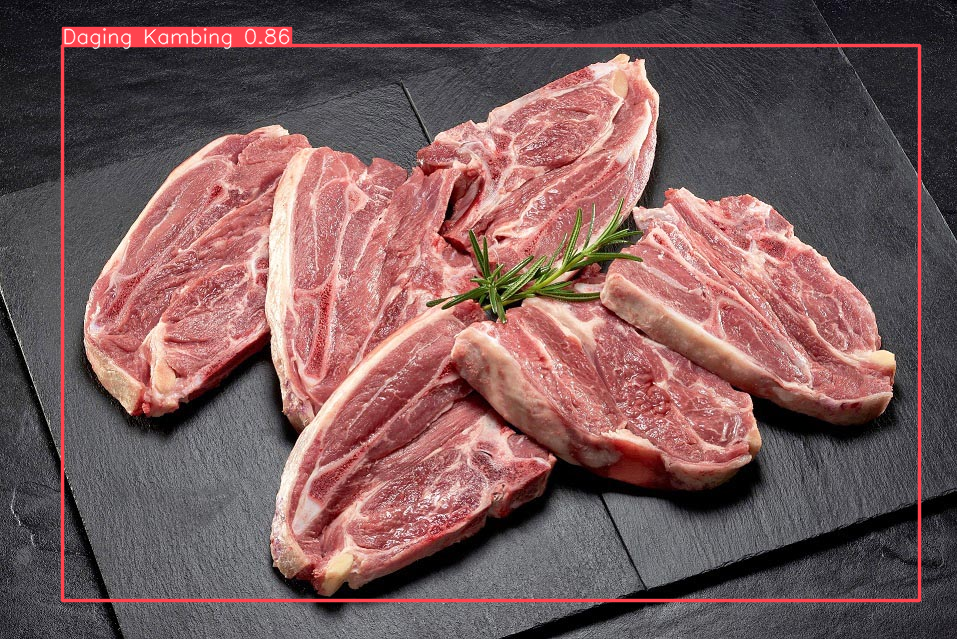

,bahan,confidence,confidence_persen
0,Daging Kambing,0.8557,85.57



Hasil gambar tersimpan di: /content/ChefAI/inference/test_photo


In [ ]:

# ============================================
# CELL 8 — INFERENCE DETECTION CHEFAI
# Tujuan:
# 1. Upload foto bahan makanan
# 2. Deteksi objek menggunakan model terbaik
# 3. Tampilkan nama kelas dan confidence
# ============================================

from pathlib import Path
from google.colab import files
from IPython.display import display, Image as DisplayImage
from ultralytics import YOLO
import pandas as pd

# 1. Lokasi model terbaik hasil training
BEST_MODEL = Path(
    "/content/ChefAI/runs/yolov8n_chefai_v1/weights/best.pt"
)

assert BEST_MODEL.exists(), (
    f"Model tidak ditemukan: {BEST_MODEL}. "
    "Pastikan Cell 8 berhasil."
)

# 2. Muat model
model = YOLO(str(BEST_MODEL))
print("Model ChefAI berhasil dimuat.")

# 3. Upload foto untuk pengujian
uploaded = files.upload()

if not uploaded:
    raise ValueError("Belum ada foto yang di-upload.")

image_path = next(iter(uploaded.keys()))
print("Foto pengujian:", image_path)

# 4. Jalankan deteksi
results = model.predict(
    source=image_path,
    conf=0.25,
    iou=0.45,
    imgsz=640,
    save=True,
    project="/content/ChefAI/inference",
    name="test_photo",
    exist_ok=True
)

# 5. Tampilkan gambar hasil deteksi
result = results[0]
annotated_image = result.plot()

from PIL import Image
display(Image.fromarray(annotated_image[:, :, ::-1]))

# 6. Tampilkan tabel deteksi
detections = []

for box in result.boxes:
    class_id = int(box.cls[0])
    confidence = float(box.conf[0])

    detections.append({
        "bahan": model.names[class_id],
        "confidence": round(confidence, 4),
        "confidence_persen": round(confidence * 100, 2)
    })

if detections:
    df = pd.DataFrame(detections)
    display(df)
else:
    print("Tidak ada objek terdeteksi.")
    print("Coba foto yang lebih jelas atau evaluasi confidence threshold.")

print(
    "\nHasil gambar tersimpan di:",
    "/content/ChefAI/inference/test_photo"
)


Cell 8 — Analisis hasil deteksi dan evaluasi per kelas untuk ChefAI

 Kita akan melihat kelas mana yang masih sering salah dikenali, khususnya Tomat dan Cabai Merah.

In [ ]:

# ============================================
# CELL 8 — EVALUASI PER KELAS
# Proyek: ChefAI - AI Vision
# ============================================

from pathlib import Path
from ultralytics import YOLO
import pandas as pd

BEST_MODEL = Path(
    "/content/ChefAI/runs/yolov8n_chefai_v1/weights/best.pt"
)
# Perbaikan typo: mengubah 'Ingredients-2' menjadi 'Ingridients-2'
DATA_YAML = "/content/Ingridients-2/data_che fai.yaml"

assert BEST_MODEL.exists(), f"Model tidak ditemukan: {BEST_MODEL}"

model = YOLO(str(BEST_MODEL))

# Evaluasi pada validation set
metrics = model.val(
    data=DATA_YAML,
    split="val",
    imgsz=640,
    plots=True,
    verbose=True
)

# Ringkasan metrik keseluruhan
print("\n=== METRIK KESELURUHAN ===")
print(f"Precision : {metrics.box.mp:.4f}")
print(f"Recall    : {metrics.box.mr:.4f}")
print(f"mAP50     : {metrics.box.map50:.4f}")
print(f"mAP50-95  : {metrics.box.map:.4f}")

# Metrik per kelas jika tersedia pada versi Ultralytics ini
names = model.names
ap50 = metrics.box.ap50
ap = metrics.box.ap

rows = []

for i, class_name in names.items():
    rows.append({
        "class_id": i,
        "kelas": class_name,
        "mAP50": float(ap50[i]) if i < len(ap50) else None,
        "mAP50_95": float(ap[i]) if i < len(ap) else None
    })

df_class = pd.DataFrame(rows)
df_class = df_class.sort_values("mAP50", na_position="first")

print("\n=== HASIL PER KELAS ===")
display(df_class)

# Simpan laporan CSV
report_dir = Path("/content/ChefAI")
report_dir.mkdir(parents=True, exist_ok=True)

csv_path = report_dir / "evaluasi_per_kelas.csv"
df_class.to_csv(csv_path, index=False)

print("\nLaporan tersimpan:", csv_path)


Ultralytics 8.4.187 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,137,567 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1160.6±483.7 MB/s, size: 22.0 KB)
val: Scanning /content/Ingridients-2/valid/labels.cache... 431 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 431/431 150.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 27/27 5.1it/s 5.3s
                   all        431        514      0.912      0.881      0.918      0.746
                  Ayam         20         28       0.94          1      0.994      0.942
          Bawang Merah         20         35      0.774      0.886      0.938       0.76
          Bawang Putih         19         22      0.887      0.636      0.725      0.544
                 Bayam         19         19      0.897          1      0.979      0.617
           Cabai Hijau         20        

,class_id,kelas,mAP50,mAP50_95
16,16,Tempe,0.718118,0.587856
2,2,Bawang Putih,0.724651,0.543724
17,17,Terong,0.763863,0.609092
9,9,Ikan,0.790500,0.678023
7,7,Daging Sapi,0.869741,0.768620
4,4,Cabai Hijau,0.897363,0.740106
18,18,Tomat,0.907688,0.631215
12,12,Kol,0.908445,0.741959
6,6,Daging Kambing,0.912520,0.722988
1,1,Bawang Merah,0.937983,0.759585



Laporan tersimpan: /content/ChefAI/evaluasi_per_kelas.csv


Cell 9 — Evaluasi per kelas

Tujuan: menghitung metrik evaluasi pada validation set dan menampilkan kelas dengan performa deteksi tertinggi maupun terendah.

In [ ]:
# ============================================
# CELL 9 — ANALISIS EVALUASI PER KELAS
# Proyek: ChefAI - AI Vision
# ============================================

from pathlib import Path
from ultralytics import YOLO
import pandas as pd

MODEL_PATH = Path(
    "/content/ChefAI/runs/yolov8n_chefai_v1/weights/best.pt"
)
# Menggunakan path folder yang benar 'Ingridients-2'
DATA_YAML = Path("/content/Ingridients-2/data_che fai.yaml")

assert MODEL_PATH.exists(), (
    f"Model tidak ditemukan: {MODEL_PATH}. Pastikan training selesai."
)
assert DATA_YAML.exists(), (
    f"Konfigurasi dataset tidak ditemukan: {DATA_YAML}"
)

# 1. Muat model terbaik
model = YOLO(str(MODEL_PATH))

# 2. Evaluasi pada validation set
metrics = model.val(
    data=str(DATA_YAML),
    split="val",
    imgsz=640,
    plots=True,
    verbose=True
)

# 3. Tampilkan metrik keseluruhan
print("\n=== METRIK KESELURUHAN ===")
print(f"Precision : {metrics.box.mp:.4f}")
print(f"Recall    : {metrics.box.mr:.4f}")
print(f"mAP50     : {metrics.box.map50:.4f}")
print(f"mAP50-95  : {metrics.box.map:.4f}")

# 4. Buat tabel metrik per kelas
class_names = model.names
ap50_values = metrics.box.ap50
ap_values = metrics.box.ap

rows = []

for class_id, class_name in class_names.items():
    rows.append({
        "ID": class_id,
        "Kelas": class_name,
        "mAP50": round(float(ap50_values[class_id]), 4)
            if class_id < len(ap50_values) else None,
        "mAP50-95": round(float(ap_values[class_id]), 4)
            if class_id < len(ap_values) else None
    })

df = pd.DataFrame(rows)

print("\n=== HASIL EVALUASI PER KELAS ===")
display(df)

# 5. Sorot kelas yang ingin diperiksa
print("\n=== FOKUS TOMAT DAN CABAI MERAH ===")
focus = df[df["Kelas"].str.lower().isin(["tomat", "cabai merah"])]
display(focus)

# 6. Simpan laporan
output_path = Path("/content/ChefAI/evaluasi_per_kelas.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(output_path, index=False)

print("Laporan tersimpan:", output_path)

Ultralytics 8.4.187 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,137,567 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1602.2±596.7 MB/s, size: 34.7 KB)
val: Scanning /content/Ingridients-2/valid/labels.cache... 431 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 431/431 150.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 27/27 5.0it/s 5.4s
                   all        431        514      0.912      0.881      0.918      0.746
                  Ayam         20         28       0.94          1      0.994      0.942
          Bawang Merah         20         35      0.774      0.886      0.938       0.76
          Bawang Putih         19         22      0.887      0.636      0.725      0.544
                 Bayam         19         19      0.897          1      0.979      0.617
           Cabai Hijau         20        

,ID,Kelas,mAP50,mAP50-95
0,0,Ayam,0.9940,0.9423
1,1,Bawang Merah,0.9380,0.7596
2,2,Bawang Putih,0.7247,0.5437
3,3,Bayam,0.9792,0.6168
4,4,Cabai Hijau,0.8974,0.7401
5,5,Cabai Merah,0.9835,0.9031
6,6,Daging Kambing,0.9125,0.7230
7,7,Daging Sapi,0.8697,0.7686
8,8,Daun Bawang,0.9950,0.7412
9,9,Ikan,0.7905,0.6780



=== FOKUS TOMAT DAN CABAI MERAH ===


,ID,Kelas,mAP50,mAP50-95
5,5,Cabai Merah,0.9835,0.9031
18,18,Tomat,0.9077,0.6312


Laporan tersimpan: /content/ChefAI/evaluasi_per_kelas.csv


Cell 10 — Confusion Matrix
*italicized text*

Tujuan: memvisualisasikan hasil evaluasi model untuk membantu mengidentifikasi kesalahan klasifikasi antar kelas.

Ultralytics 8.4.187 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,137,567 parameters, 0 gradients, 8.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 970.6±448.3 MB/s, size: 33.1 KB)
val: Scanning /content/Ingridients-2/valid/labels.cache... 431 images, 1 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 431/431 82.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 27/27 4.9it/s 5.5s
                   all        431        514      0.912      0.881      0.918      0.746
                  Ayam         20         28       0.94          1      0.994      0.942
          Bawang Merah         20         35      0.774      0.886      0.938       0.76
          Bawang Putih         19         22      0.887      0.636      0.725      0.544
                 Bayam         19         19      0.897          1      0.979      0.617
           Cabai Hijau         20         2

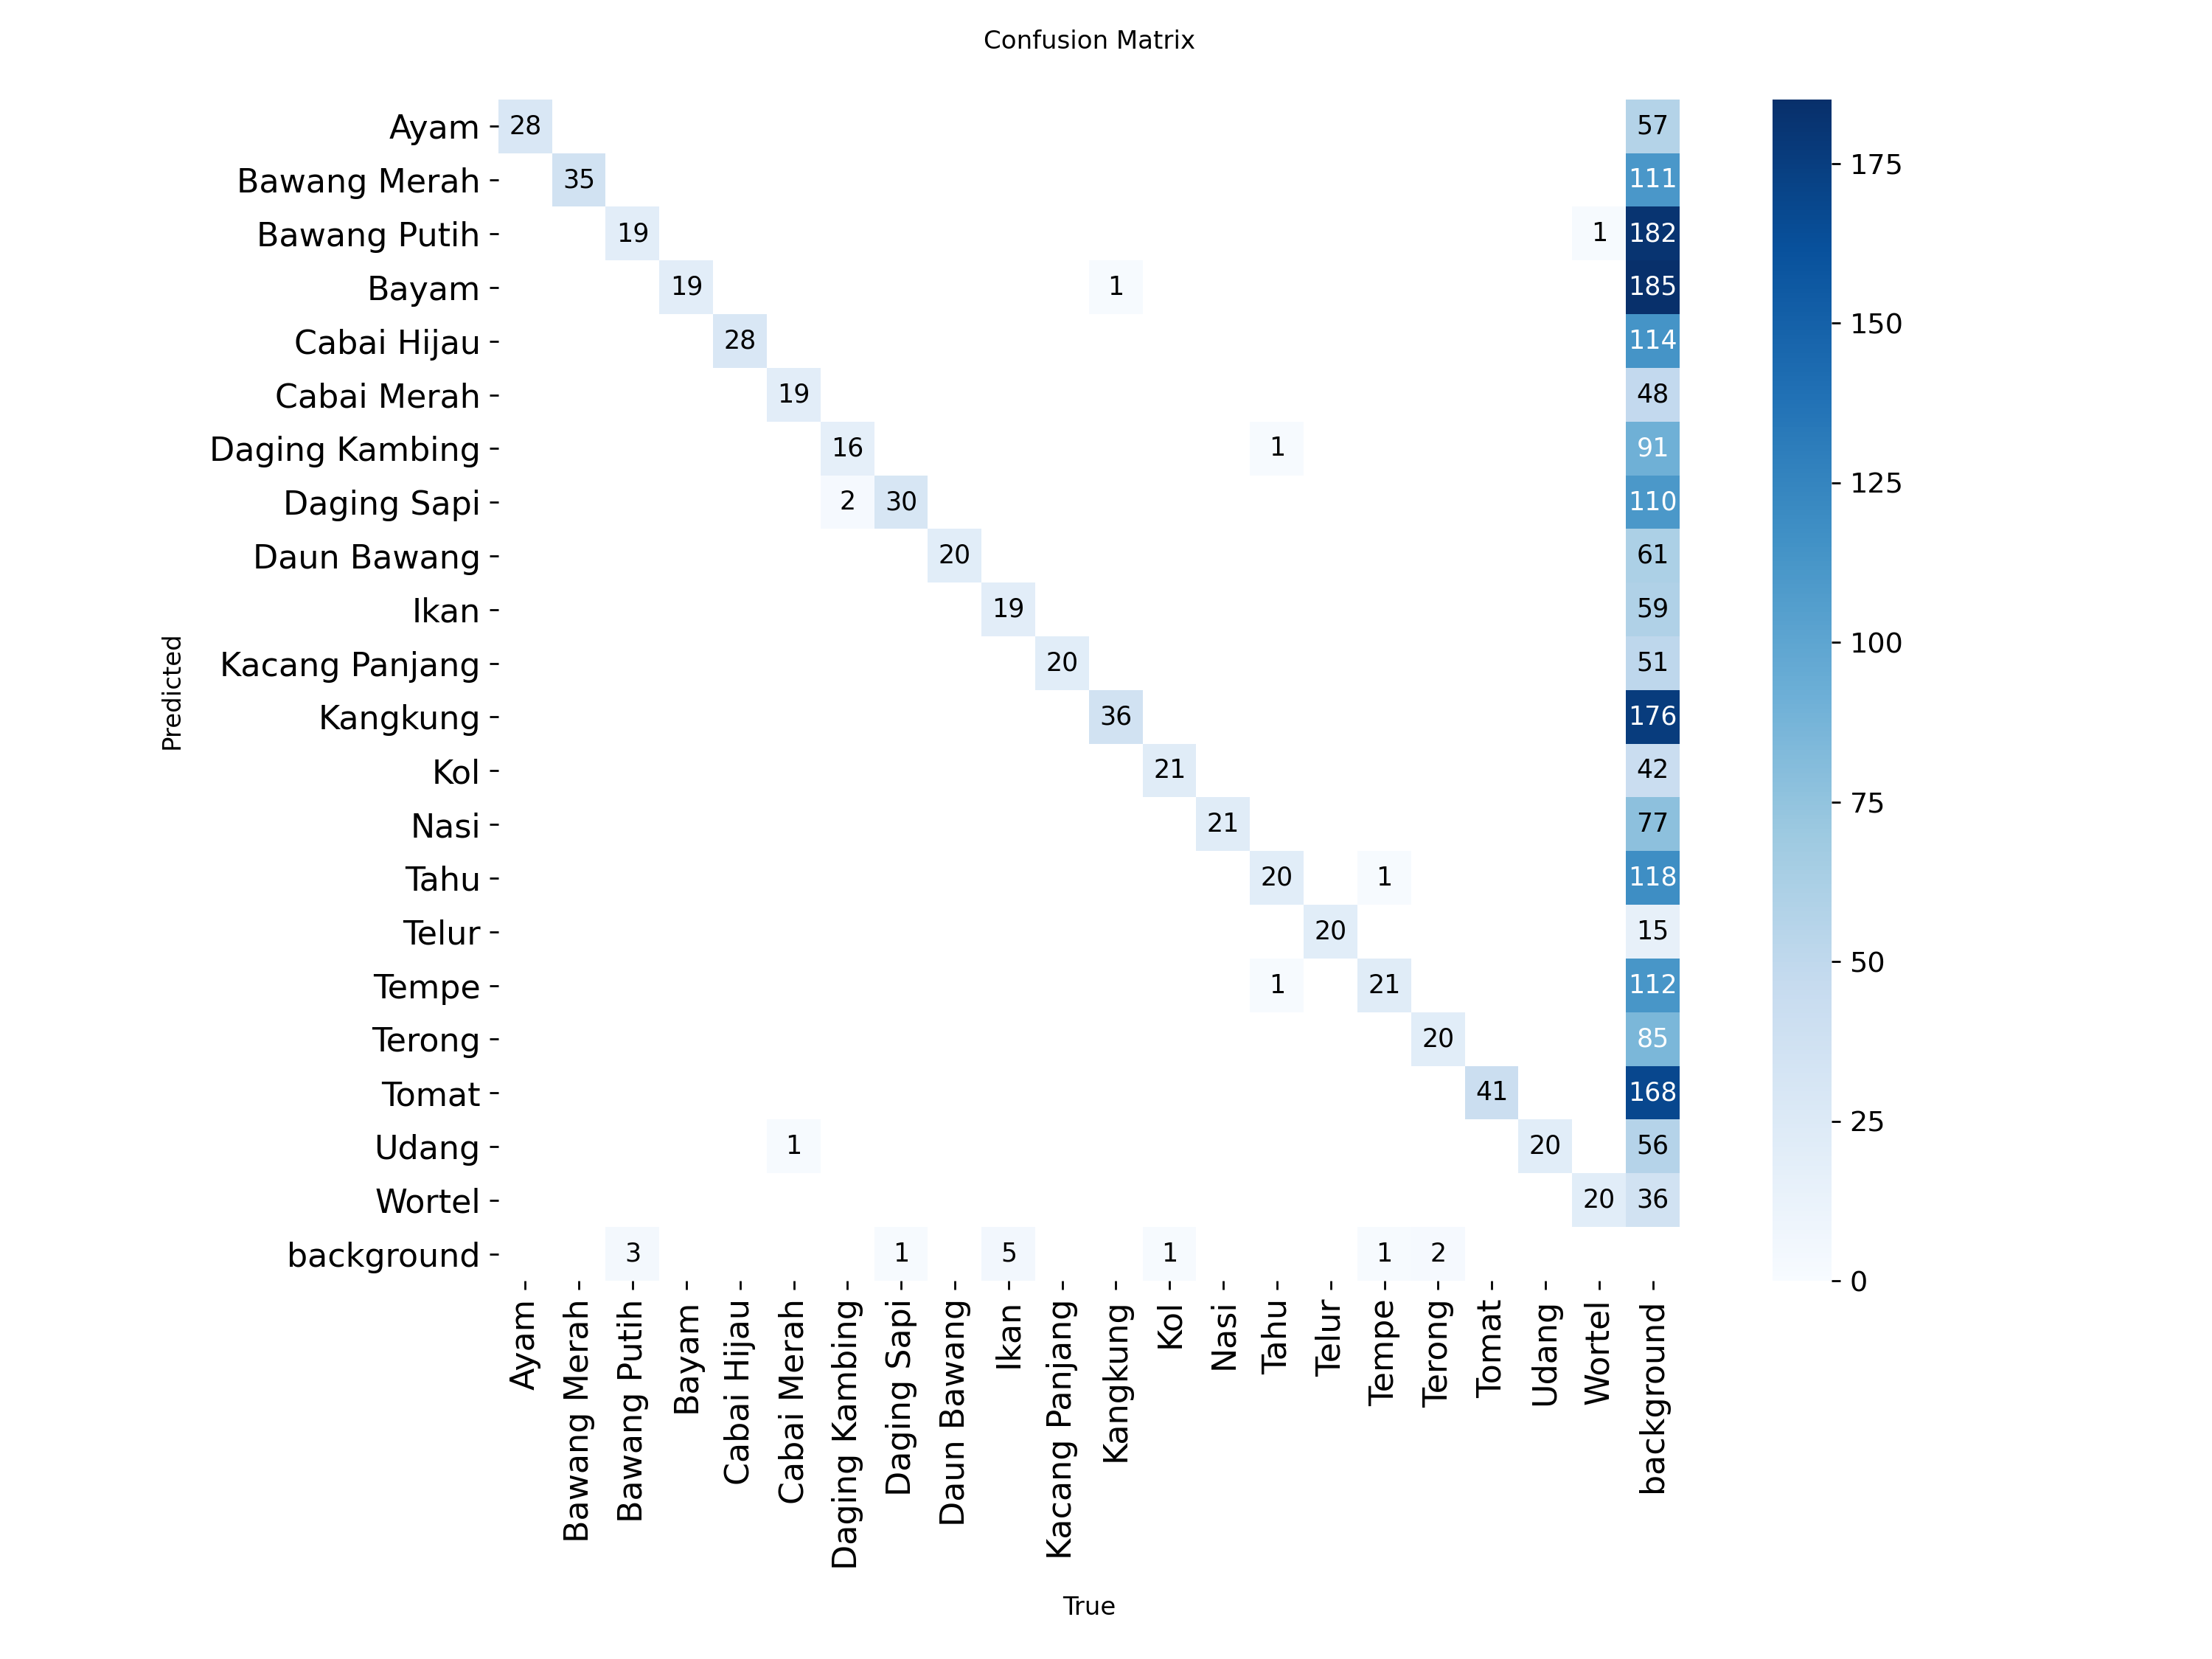


Menampilkan: confusion_matrix_normalized.png


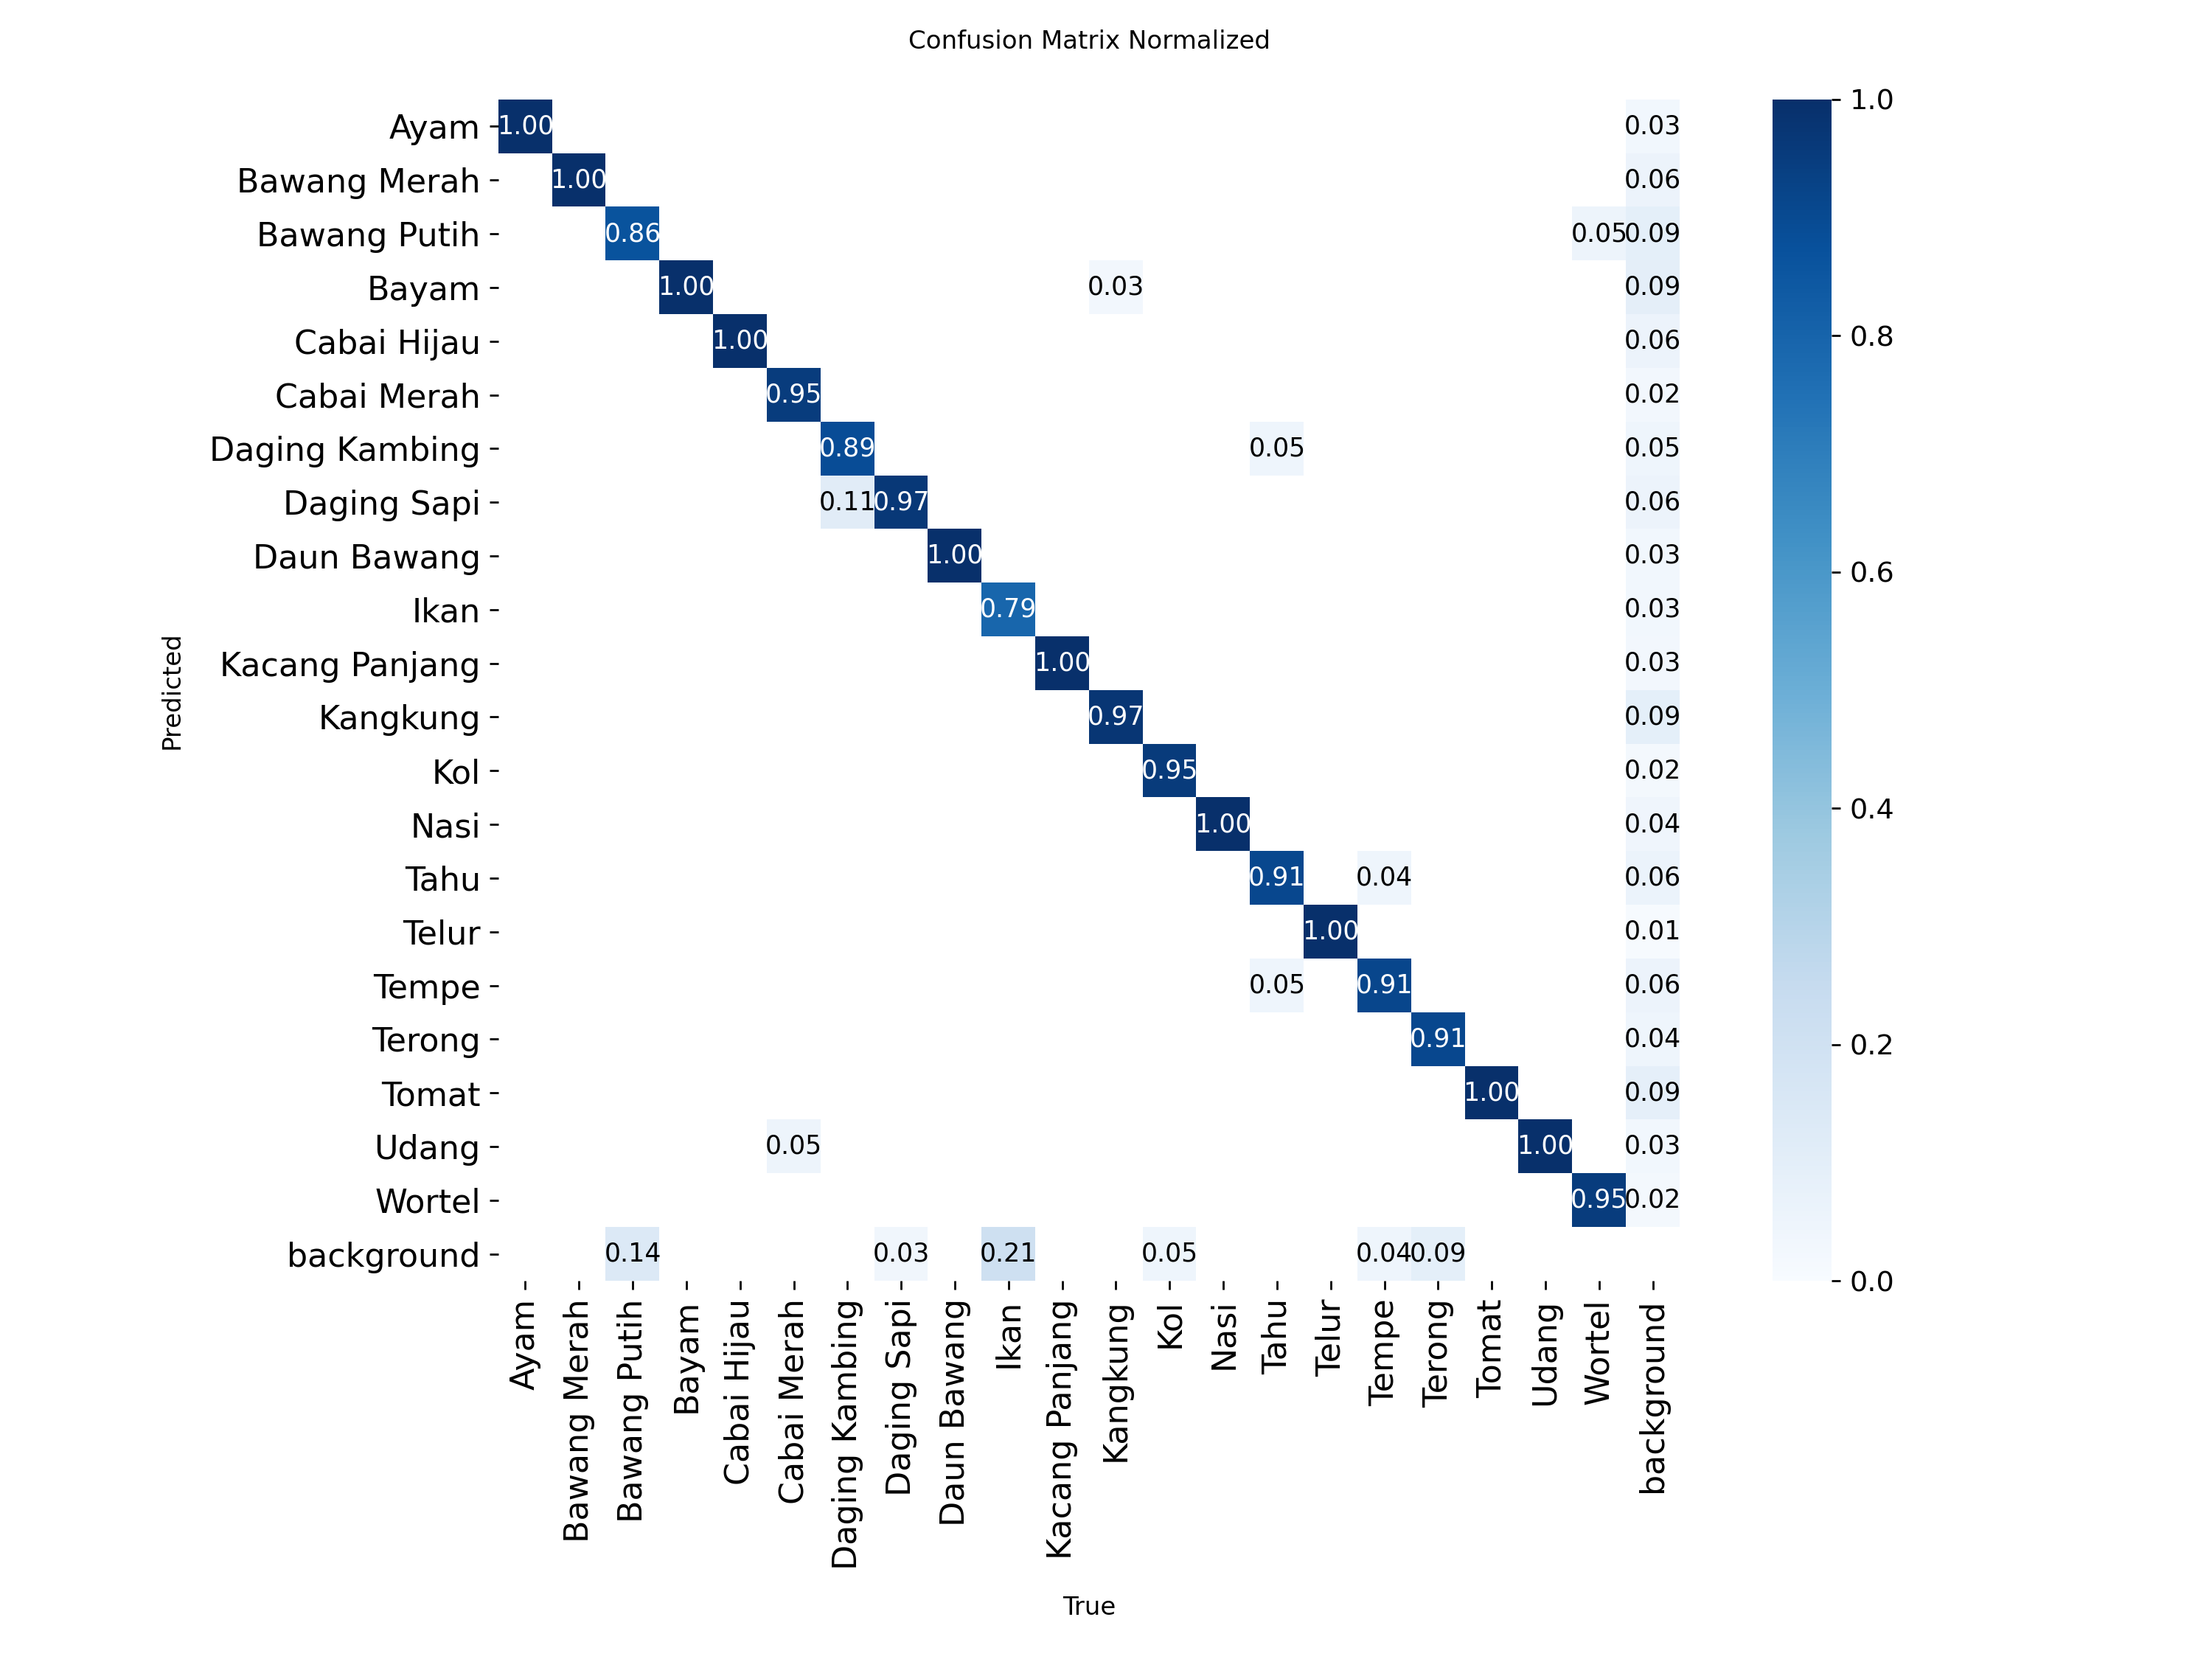

In [ ]:

# ============================================
# CELL 10 — CONFUSION MATRIX CHEFAI
# Tujuan:
# Melihat pola kesalahan deteksi antar kelas
# ============================================

from pathlib import Path
from ultralytics import YOLO
from IPython.display import display, Image
import glob

MODEL_PATH = (
    "/content/ChefAI/runs/yolov8n_chefai_v1/weights/best.pt"
)
# Perbaikan typo: mengubah 'Ingredients-2' menjadi 'Ingridients-2'
DATA_YAML = "/content/Ingridients-2/data_che fai.yaml"

assert Path(MODEL_PATH).exists(), "Model best.pt tidak ditemukan."

model = YOLO(MODEL_PATH)

# Evaluasi validation set dan buat plot evaluasi
metrics = model.val(
    data=DATA_YAML,
    split="val",
    imgsz=640,
    plots=True,
    verbose=True
)

print("Evaluasi selesai.")
print("Lokasi folder evaluasi:", metrics.save_dir)

# Cari file confusion matrix yang dihasilkan Ultralytics
save_dir = Path(metrics.save_dir)

possible_files = [
    save_dir / "confusion_matrix.png",
    save_dir / "confusion_matrix_normalized.png"
]

found = False

for plot_path in possible_files:
    if plot_path.exists():
        print("\nMenampilkan:", plot_path.name)
        display(Image(filename=str(plot_path)))
        found = True

if not found:
    print(
        "Confusion matrix tidak ditemukan pada folder evaluasi ini. "
        "Periksa isi folder:"
    )
    for p in save_dir.iterdir():
        print("-", p.name)


Cell 11 — Simpan model final dan laporan

Kalau evaluasi sudah selesai, gunakan cell berikut untuk mengumpulkan model dan laporan ke satu folder.

In [ ]:

# ============================================
# CELL 11 — PERSIAPAN MODEL FINAL CHEFAI
# ============================================

from pathlib import Path
import shutil
import json

MODEL_PATH = Path(
    "/content/ChefAI/runs/yolov8n_chefai_v1/weights/best.pt"
)
EXPORT_DIR = Path("/content/ChefAI/export")

assert MODEL_PATH.exists(), "best.pt tidak ditemukan."

EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# Salin model terbaik
final_model = EXPORT_DIR / "chefai_best.pt"
shutil.copy2(MODEL_PATH, final_model)

# Salin konfigurasi kelas
yaml_path = Path("/content/Ingredients-2/data_che fai.yaml")
if yaml_path.exists():
    shutil.copy2(yaml_path, EXPORT_DIR / "data.yaml")

# Salin laporan evaluasi jika sudah dibuat
for filename in [
    "evaluasi_per_kelas.csv",
    "evaluation_report.json"
]:
    source = Path("/content/ChefAI") / filename
    if source.exists():
        shutil.copy2(source, EXPORT_DIR / filename)

print("=== FILE MODEL FINAL ===")
for path in sorted(EXPORT_DIR.iterdir()):
    print(f"{path.name} — {path.stat().st_size / (1024 * 1024):.2f} MB")

print("\nModel final:", final_model)
print("Catatan: ekspor tidak memperbaiki kesalahan prediksi secara otomatis.")


=== FILE MODEL FINAL ===
chefai_best.pt — 6.21 MB
evaluasi_per_kelas.csv — 0.00 MB
evaluation_report.json — 0.00 MB

Model final: /content/ChefAI/export/chefai_best.pt
Catatan: ekspor tidak memperbaiki kesalahan prediksi secara otomatis.


Cell 12 — Validasi file model dan laporan

Tujuan: memastikan file model dapat dimuat dan laporan evaluasi berisi data.

In [ ]:

# ============================================
# CELL 12 — VALIDASI MODEL FINAL CHEFAI
# ============================================

from pathlib import Path
from ultralytics import YOLO
import pandas as pd
import json

EXPORT_DIR = Path("/content/ChefAI/export")
MODEL_PATH = EXPORT_DIR / "chefai_best.pt"

# 1. Periksa ukuran file
print("=== PEMERIKSAAN FILE ===")
for path in sorted(EXPORT_DIR.iterdir()):
    print(f"{path.name}: {path.stat().st_size:,} bytes")

# 2. Pastikan model bisa dimuat
assert MODEL_PATH.exists(), "Model final tidak ditemukan."
model = YOLO(str(MODEL_PATH))

print("\nModel berhasil dimuat.")
print("Jumlah kelas:", len(model.names))
print("Nama kelas:")
for class_id, name in model.names.items():
    print(f"{class_id}: {name}")

# 3. Periksa laporan CSV
csv_path = EXPORT_DIR / "evaluasi_per_kelas.csv"

if csv_path.exists() and csv_path.stat().st_size > 0:
    df = pd.read_csv(csv_path)
    print("\n=== LAPORAN EVALUASI PER KELAS ===")
    display(df)
else:
    print("\nLaporan CSV tidak ditemukan atau kosong.")

# 4. Periksa laporan JSON
json_path = EXPORT_DIR / "evaluation_report.json"

if json_path.exists() and json_path.stat().st_size > 0:
    with open(json_path, "r", encoding="utf-8") as f:
        report = json.load(f)
    print("\n=== LAPORAN EVALUASI JSON ===")
    print(json.dumps(report, indent=2))
else:
    print("\nLaporan JSON tidak ditemukan atau kosong.")


=== PEMERIKSAAN FILE ===
chefai_best.pt: 6,516,522 bytes
evaluasi_per_kelas.csv: 541 bytes
evaluation_report.json: 133 bytes

Model berhasil dimuat.
Jumlah kelas: 21
Nama kelas:
0: Ayam
1: Bawang Merah
2: Bawang Putih
3: Bayam
4: Cabai Hijau
5: Cabai Merah
6: Daging Kambing
7: Daging Sapi
8: Daun Bawang
9: Ikan
10: Kacang Panjang
11: Kangkung
12: Kol
13: Nasi
14: Tahu
15: Telur
16: Tempe
17: Terong
18: Tomat
19: Udang
20: Wortel

=== LAPORAN EVALUASI PER KELAS ===


,ID,Kelas,mAP50,mAP50-95
0,0,Ayam,0.9940,0.9423
1,1,Bawang Merah,0.9380,0.7596
2,2,Bawang Putih,0.7247,0.5437
3,3,Bayam,0.9792,0.6168
4,4,Cabai Hijau,0.8974,0.7401
5,5,Cabai Merah,0.9835,0.9031
6,6,Daging Kambing,0.9125,0.7230
7,7,Daging Sapi,0.8697,0.7686
8,8,Daun Bawang,0.9950,0.7412
9,9,Ikan,0.7905,0.6780



=== LAPORAN EVALUASI JSON ===
{
  "precision": 0.9120174343368387,
  "recall": 0.880854615627843,
  "mAP50": 0.9183363669501803,
  "mAP50_95": 0.7461768057176865
}


Cell 13 — Uji model final dengan foto baru

Tujuan: memastikan file ekspor chefai_best.pt dapat melakukan inferensi, bukan hanya tersimpan.

Upload satu foto bahan makanan untuk pengujian.


Saving 53129c912937d691af6588e3943fb3e5.jpg to 53129c912937d691af6588e3943fb3e5 (1).jpg

image 1/1 /content/53129c912937d691af6588e3943fb3e5 (1).jpg: 640x640 1 Bayam, 12.5ms
Speed: 2.0ms preprocess, 12.5ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/ChefAI/inference/final_test


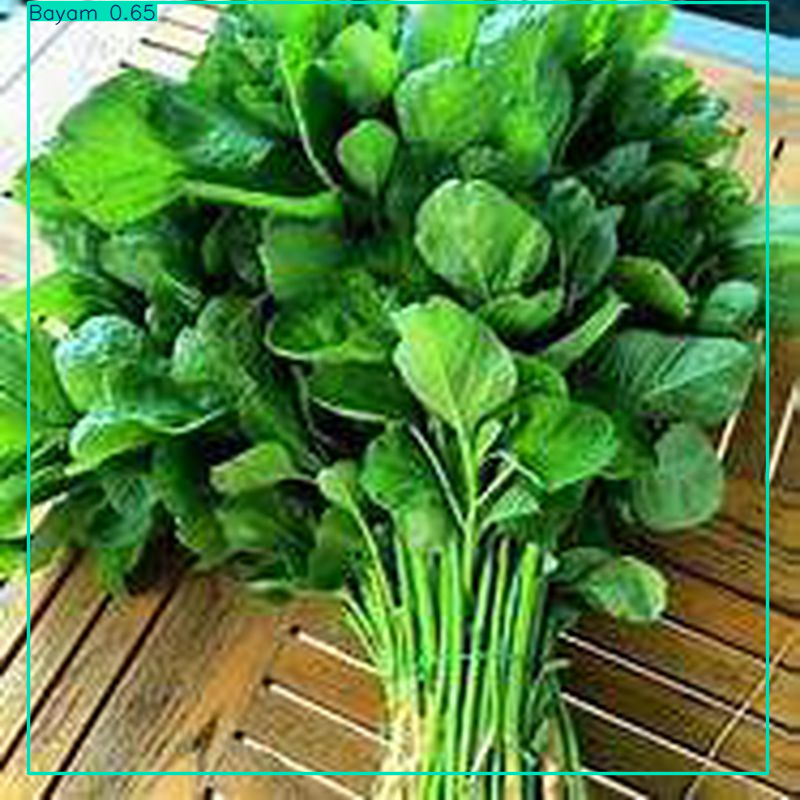

,Bahan,Confidence (%)
0,Bayam,64.57


In [ ]:

# ============================================
# CELL 17 — UJI INFERENCE MODEL FINAL
# ============================================

from google.colab import files
from IPython.display import display
from PIL import Image
from ultralytics import YOLO
from pathlib import Path
import pandas as pd

MODEL_PATH = Path("/content/ChefAI/export/chefai_best.pt")
assert MODEL_PATH.exists(), "Model final belum tersedia."

model = YOLO(str(MODEL_PATH))

print("Upload satu foto bahan makanan untuk pengujian.")
uploaded = files.upload()

if not uploaded:
    raise ValueError("Tidak ada foto yang di-upload.")

image_path = next(iter(uploaded))

results = model.predict(
    source=image_path,
    imgsz=640,
    conf=0.25,
    save=True,
    project="/content/ChefAI/inference",
    name="final_test",
    exist_ok=True
)

result = results[0]
display(Image.fromarray(result.plot()[:, :, ::-1]))

rows = []
for box in result.boxes:
    class_id = int(box.cls[0])
    conf = float(box.conf[0])
    rows.append({
        "Bahan": model.names[class_id],
        "Confidence (%)": round(conf * 100, 2)
    })

if rows:
    df = pd.DataFrame(rows).sort_values(
        "Confidence (%)", ascending=False
    )
    display(df)
else:
    print("Tidak ada objek terdeteksi dengan threshold 0.25.")


Cell 14 — 📦 Paket model ChefAI untuk diunduh

Tujuan: membuat satu file ZIP yang berisi model, konfigurasi dataset, dan laporan evaluasi yang tersedia.

In [ ]:

# CELL 14 — Kemas model ChefAI untuk diunduh

from pathlib import Path
import zipfile

BASE_DIR = Path("/content/ChefAI")
EXPORT_DIR = BASE_DIR / "export"
ZIP_PATH = BASE_DIR / "ChefAI_model_package.zip"

# File yang akan dimasukkan ke ZIP
files_to_package = [
    EXPORT_DIR / "chefai_best.pt",
    EXPORT_DIR / "evaluasi_per_kelas.csv",
    EXPORT_DIR / "evaluation_report.json",
    EXPORT_DIR / "data.yaml",
]

# Tambahkan hasil training jika tersedia
files_to_package += [
    BASE_DIR / "runs/yolov8n_chefai_v1/results.csv",
    BASE_DIR / "runs/yolov8n_chefai_v1/results.png",
    BASE_DIR / "runs/yolov8n_chefai_v1/confusion_matrix.png",
]

# Periksa file sebelum dikemas
available_files = [
    path for path in files_to_package
    if path.exists() and path.is_file() and path.stat().st_size > 0
]

if not available_files:
    raise FileNotFoundError(
        "Tidak ada file yang siap dikemas. "
        "Periksa kembali lokasi model hasil training."
    )

with zipfile.ZipFile(
    ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED
) as zipf:
    for path in available_files:
        zipf.write(path, arcname=path.name)

print("Paket ChefAI berhasil dibuat.")
print(f"Lokasi ZIP: {ZIP_PATH}")
print(f"Ukuran ZIP: {ZIP_PATH.stat().st_size / (1024**2):.2f} MB")
print("\nFile yang dimasukkan:")

for path in available_files:
    print(f"- {path.name} ({path.stat().st_size:,} bytes)")

# Unduh ke komputer
from google.colab import files
files.download(str(ZIP_PATH))


Paket ChefAI berhasil dibuat.
Lokasi ZIP: /content/ChefAI/ChefAI_model_package.zip
Ukuran ZIP: 6.21 MB

File yang dimasukkan:
- chefai_best.pt (6,516,522 bytes)
- evaluasi_per_kelas.csv (541 bytes)
- evaluation_report.json (133 bytes)
- results.csv (6,259 bytes)
- results.png (308,209 bytes)
- confusion_matrix.png (349,011 bytes)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>